# Expectation maximization for Gaussian mixtures

**Gabriel Trabelsi**

Estimate the weight, means and variances of a two-component univariate Gaussian mixture. Existing experiments examine initialization, iteration count, sample size and model misspecification.

**Academic context:** the supplied `TP7_ExpectationMaximization-stud` practical notebook in Statistiques computationnelles. The notebook combines teaching scaffolding with completed implementation and experiments; see [attribution](../docs/attribution.md).

Figures and outputs are retained from the original notebook. Random draws and timings may differ on a new run; historical execution counters have been cleared.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st


## 1. Simulated observations

Two Gaussian components have means -2 and 3, standard deviations 1.5 and 1, and first-component weight 0.3.

(array([  1.,   0.,   0.,   0.,   4.,  11.,  13.,  10.,  17.,  45.,  46.,
         77.,  74., 116., 131., 154., 182., 184., 202., 223., 242., 241.,
        187., 171., 128., 117.,  90.,  80.,  85., 118., 153., 270., 378.,
        534., 634., 743., 791., 788., 771., 630., 475., 349., 213., 142.,
         91.,  50.,  23.,   9.,   3.,   4.]),
 array([-7.55973393, -7.27454499, -6.98935606, -6.70416713, -6.41897819,
        -6.13378926, -5.84860032, -5.56341139, -5.27822246, -4.99303352,
        -4.70784459, -4.42265565, -4.13746672, -3.85227779, -3.56708885,
        -3.28189992, -2.99671098, -2.71152205, -2.42633312, -2.14114418,
        -1.85595525, -1.57076631, -1.28557738, -1.00038845, -0.71519951,
        -0.43001058, -0.14482164,  0.14036729,  0.42555622,  0.71074516,
         0.99593409,  1.28112303,  1.56631196,  1.85150089,  2.13668983,
         2.42187876,  2.7070677 ,  2.99225663,  3.27744556,  3.5626345 ,
         3.84782343,  4.13301237,  4.4182013 ,  4.70339023,  4.98857917,
 

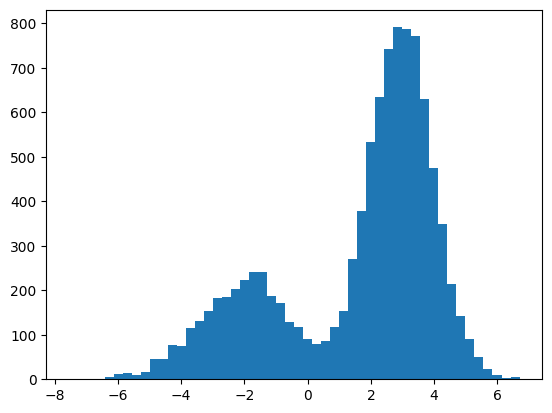

In [ ]:
# number of observations
n_samples = 10000

# means and variance to be estimated
mu1, sigma1 = -2, 1.5
mu2, sigma2 = 3, 1

# prior probability of the first cluster/goup
pi1 = 0.3

prior = np.random.choice([0,1], size=n_samples, p = [1-pi1, pi1])
sample = np.array([st.norm.rvs(loc=mu1, scale=sigma1) if c==1 else st.norm.rvs(loc=mu2, scale=sigma2) for c in prior])
plt.hist(sample, bins=50)


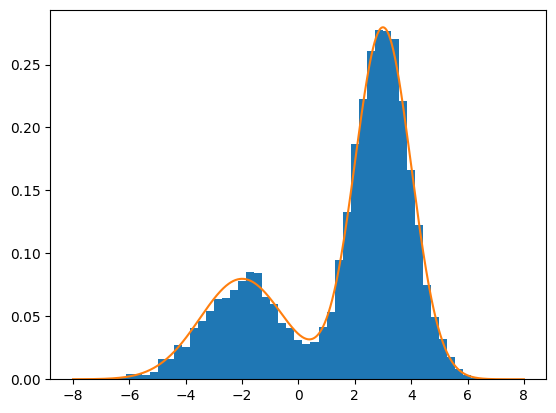

In [ ]:
def Gaussian_pdf(x, mean, variance):
  z = np.exp(-(x - mean)**2/(2*variance))/np.sqrt(2*np.pi*variance)
  return z
plt.hist(sample, bins=50, density=True)

x = np.linspace(-8, 8, 1000)
y = pi1*Gaussian_pdf(x, mu1, sigma1**2) + (1-pi1)*Gaussian_pdf(x, mu2, sigma2**2)
plt.plot(x, y)


## 2. E-step and M-step

Responsibilities weight the updates of mixture proportion, means and variances. The implementation below uses separate component variances.

In [ ]:
n_clust = 2
weights = np.ones((n_clust)) / n_clust
means = [0, 1]
variances = [0.5, 2]


In [ ]:
# number of iterations of the EM algorithm
n_it = 100


In [ ]:
pi1_est = np.zeros(n_it+1)
mu1_est = np.zeros(n_it+1)
mu2_est = np.zeros(n_it+1)
sigma1_est = np.zeros(n_it+1)
sigma2_est = np.zeros(n_it+1)

pi1_est[0] = weights[0]
mu1_est[0] = means[0]
mu2_est[0] = means[1]
sigma1_est[0] = variances[0]
sigma2_est[0] = variances[1]


In [ ]:
for j in range(0, n_it):

    # E-step
    pdf1 = Gaussian_pdf(sample, mu1_est[j], sigma1_est[j])
    pdf2 = Gaussian_pdf(sample, mu2_est[j], sigma2_est[j])
    weights = pi1_est[j] * pdf1 / (pi1_est[j] * pdf1 + (1 - pi1_est[j]) * pdf2)

    nk = weights.sum()
    n2 = (1-weights).sum()

    pi1_est[j+1] = 1/n_samples * nk
    mu1_est[j+1] = (weights*sample/nk).sum()
    sigma1_est[j+1] = (((sample-mu1_est[j+1])**2)*weights).sum()/nk

    mu2_est[j+1] = ((1-weights)*sample).sum() / n2
    sigma2_est[j+1] = (((sample-mu2_est[j+1])**2)*(1-weights)).sum() / n2


## 3. Convergence diagnostics

The figures show the observed log-likelihood and the parameter trajectories.

(-23000.0, -20679.56523854001)

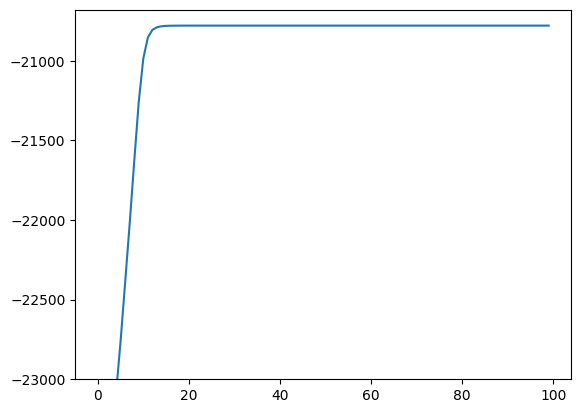

In [ ]:
def loglikmultigaussian(x, pi1, mu, sigma):
    mu1, mu2 = mu
    sigma1, sigma2 = sigma
    return np.log(pi1*Gaussian_pdf(x, mu1, sigma1) + (1-pi1)*Gaussian_pdf(x, mu2, sigma2))

loglik = [loglikmultigaussian(sample, pi1_est[j], (mu1_est[j], mu2_est[j]), (sigma1_est[j], sigma2_est[j])).sum() for j in range(n_it)]

plt.plot(loglik)
plt.ylim([-23000, max(loglik) + 100])


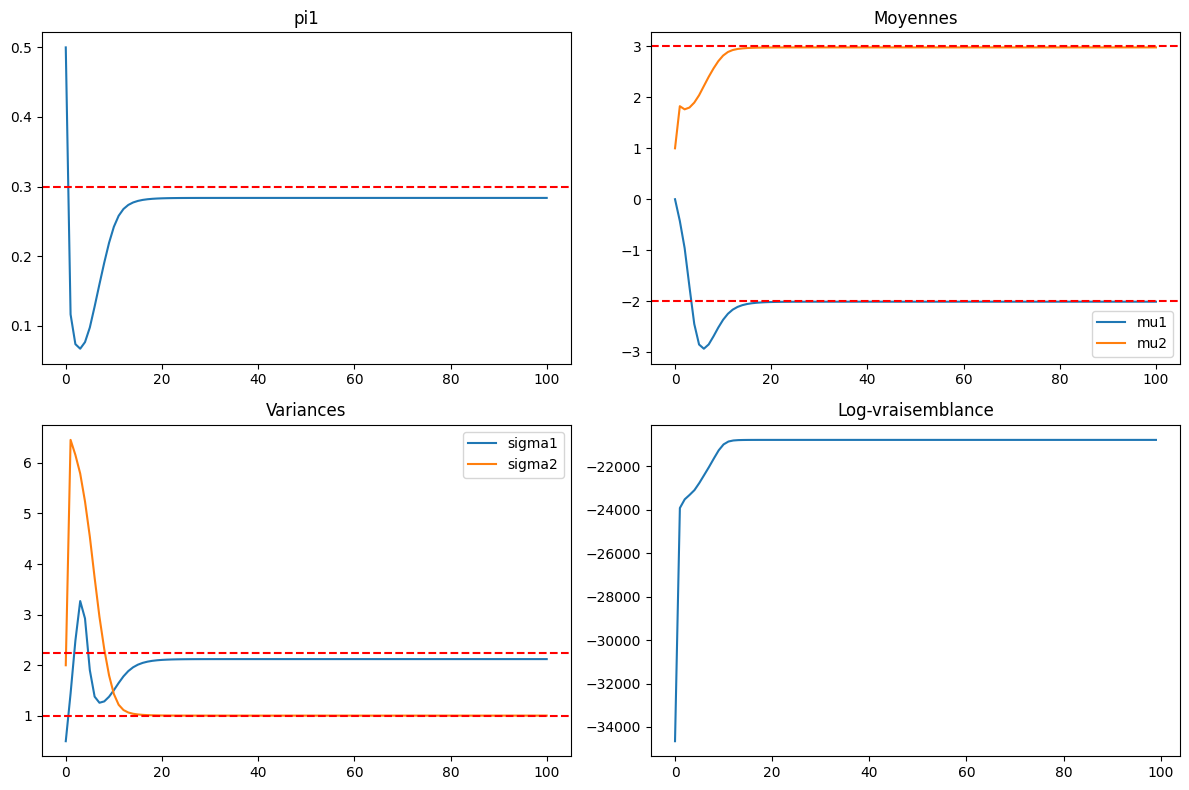

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(pi1_est)
axes[0, 0].axhline(pi1, color='r', linestyle='--')
axes[0, 0].set_title('pi1')

axes[0, 1].plot(mu1_est, label='mu1')
axes[0, 1].plot(mu2_est, label='mu2')
axes[0, 1].axhline(mu1, color='r', linestyle='--')
axes[0, 1].axhline(mu2, color='r', linestyle='--')
axes[0, 1].set_title('Moyennes')
axes[0, 1].legend()

axes[1, 0].plot(sigma1_est, label='sigma1')
axes[1, 0].plot(sigma2_est, label='sigma2')
axes[1, 0].axhline(sigma1**2, color='r', linestyle='--')
axes[1, 0].axhline(sigma2**2, color='r', linestyle='--')
axes[1, 0].set_title('Variances')
axes[1, 0].legend()

axes[1, 1].plot(loglik)
axes[1, 1].set_title('Log-vraisemblance')

plt.tight_layout()
plt.show()


## 4. Reusable EM implementation

In [ ]:
# Fonction EM réutilisable
def run_em(sample, pi1_init, mu1_init, mu2_init, s1_init, s2_init, n_it):
    n = len(sample)
    pi1_est = np.zeros(n_it+1)
    mu1_est = np.zeros(n_it+1)
    mu2_est = np.zeros(n_it+1)
    sigma1_est = np.zeros(n_it+1)
    sigma2_est = np.zeros(n_it+1)

    pi1_est[0], mu1_est[0], mu2_est[0] = pi1_init, mu1_init, mu2_init
    sigma1_est[0], sigma2_est[0] = s1_init, s2_init

    for j in range(n_it):
        pdf1 = Gaussian_pdf(sample, mu1_est[j], sigma1_est[j])
        pdf2 = Gaussian_pdf(sample, mu2_est[j], sigma2_est[j])
        omega = pi1_est[j] * pdf1 / (pi1_est[j] * pdf1 + (1 - pi1_est[j]) * pdf2)

        n1 = omega.sum()
        n2 = (1 - omega).sum()

        pi1_est[j+1] = n1 / n
        mu1_est[j+1] = (omega * sample).sum() / n1
        mu2_est[j+1] = ((1 - omega) * sample).sum() / n2
        sigma1_est[j+1] = (omega * (sample - mu1_est[j+1])**2).sum() / n1
        sigma2_est[j+1] = ((1 - omega) * (sample - mu2_est[j+1])**2).sum() / n2

    loglik = [np.log(pi1_est[j]*Gaussian_pdf(sample, mu1_est[j], sigma1_est[j])
              + (1-pi1_est[j])*Gaussian_pdf(sample, mu2_est[j], sigma2_est[j])).sum()
              for j in range(n_it+1)]

    return pi1_est, mu1_est, mu2_est, sigma1_est, sigma2_est, loglik


## 5. Initialization sensitivity

The same observed sample is fitted from several initial parameter settings.

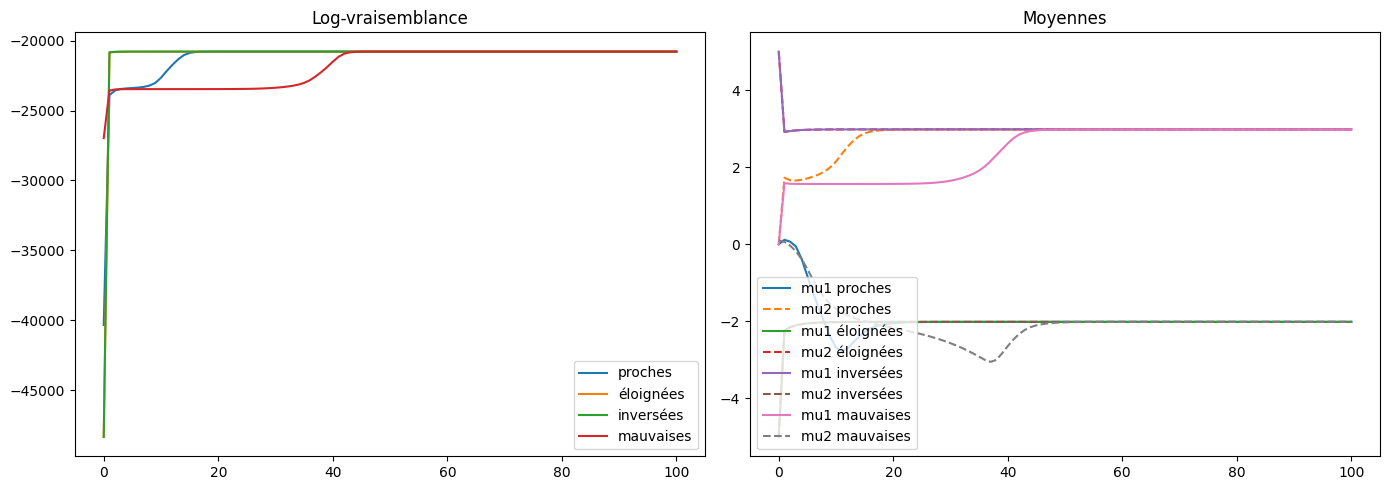

In [ ]:
inits = [
    (0.5, 0, 0.0001, 0.5, 2, "proches"),
    (0.5, -5, 5, 1, 1, "éloignées"),
    (0.5, 5, -5, 1, 1, "inversées"),
    (0.9, 0, 0.1, 5, 0.1, "mauvaises"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for pi_i, m1, m2, s1, s2, label in inits:
    _, mu1, mu2, _, _, loglik = run_em(sample, pi_i, m1, m2, s1, s2, 100)
    axes[0].plot(loglik, label=label)
    axes[1].plot(mu1, linestyle='-', label=f'mu1 {label}')
    axes[1].plot(mu2, linestyle='--', label=f'mu2 {label}')

axes[0].set_title("Log-vraisemblance"); axes[0].legend()
axes[1].set_title("Moyennes"); axes[1].legend()
plt.tight_layout(); plt.show()


## 6. Iteration budget

The same implementation is run with different maximum iteration counts.

n_it=5: mu1=-2.853, mu2=2.042
n_it=10: mu1=-2.367, mu2=2.822
n_it=20: mu1=-2.019, mu2=2.980
n_it=50: mu1=-2.012, mu2=2.982
n_it=100: mu1=-2.012, mu2=2.982


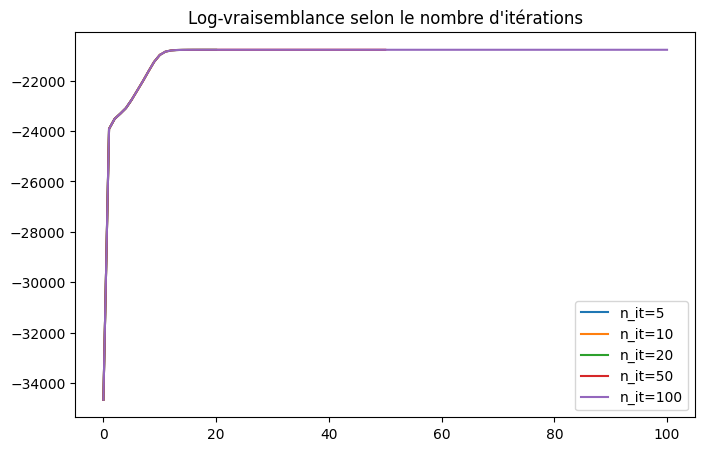

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for n_it in [5, 10, 20, 50, 100]:
    _, mu1, mu2, _, _, loglik = run_em(sample, 0.5, 0, 1, 0.5, 2, n_it)
    ax.plot(loglik, label=f'n_it={n_it}')
    print(f"n_it={n_it}: mu1={mu1[-1]:.3f}, mu2={mu2[-1]:.3f}")

ax.set_title("Log-vraisemblance selon le nombre d'itérations")
ax.legend(); plt.show()


## 7. Sample size

A new sample is generated for each size. These single realizations illustrate behaviour; they do not estimate an average learning curve.

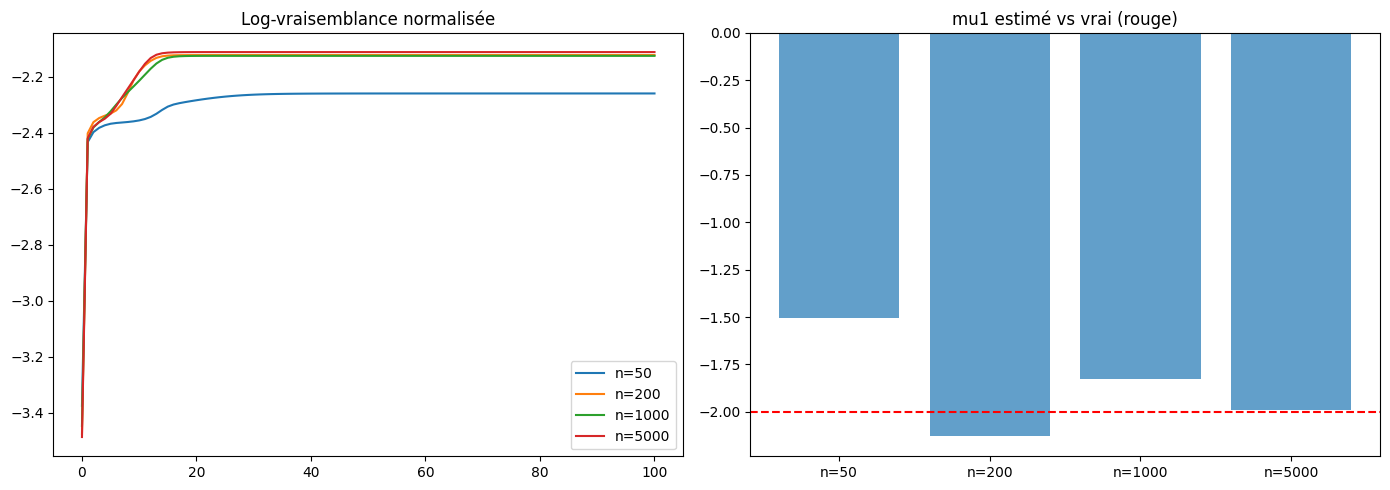

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
n_obs_list = [50, 200, 1000, 5000]
mu1_results = []

for n_obs in n_obs_list:
    prior_tmp = np.random.choice([0,1], size=n_obs, p=[1-pi1, pi1])
    sample_tmp = np.array([st.norm.rvs(loc=-2, scale=1.5) if c==1
                           else st.norm.rvs(loc=3, scale=1) for c in prior_tmp])
    pi_e, mu1_e, mu2_e, s1_e, s2_e, loglik = run_em(sample_tmp, 0.5, 0, 1, 0.5, 2, 100)
    axes[0].plot(np.array(loglik)/n_obs, label=f'n={n_obs}')
    mu1_results.append(mu1_e[-1])

axes[0].set_title("Log-vraisemblance normalisée"); axes[0].legend()

axes[1].bar([f'n={n}' for n in n_obs_list], mu1_results, alpha=0.7)
axes[1].axhline(-2, color='r', linestyle='--')
axes[1].set_title("mu1 estimé vs vrai (rouge)")
plt.tight_layout(); plt.show()


## 8. Two components fitted to three groups

The fitted model is deliberately misspecified. In the saved run, the two estimated means are close to one another; the likelihood and fitted density should be inspected together.

EM 2 clusters: mu1=0.149, mu2=0.290
Vrais centres: [-4, 0, 5]


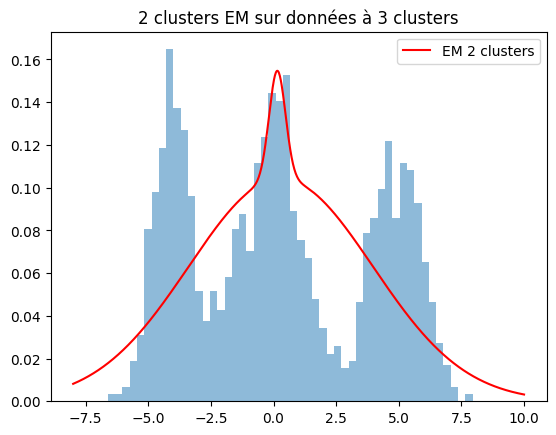

In [ ]:
# Générer des données avec 3 clusters
mu_true = [-4, 0, 5]
sigma_true = [0.8, 1.2, 1.0]
pi_true = [0.3, 0.4, 0.3]
n_obs = 2000

cluster = np.random.choice([0,1,2], size=n_obs, p=pi_true)
sample3 = np.array([st.norm.rvs(loc=mu_true[c], scale=sigma_true[c]) for c in cluster])

# EM avec 2 clusters sur des données à 3 clusters
pi1_e, mu1_e, mu2_e, s1_e, s2_e, loglik2 = run_em(sample3, 0.5, 0, 1, 0.5, 2, 100)

print(f"EM 2 clusters: mu1={mu1_e[-1]:.3f}, mu2={mu2_e[-1]:.3f}")
print(f"Vrais centres: {mu_true}")

plt.hist(sample3, bins=50, density=True, alpha=0.5)
x = np.linspace(-8, 10, 1000)
y = pi1_e[-1]*Gaussian_pdf(x, mu1_e[-1], s1_e[-1]) + (1-pi1_e[-1])*Gaussian_pdf(x, mu2_e[-1], s2_e[-1])
plt.plot(x, y, 'r', label='EM 2 clusters')
plt.legend(); plt.title("2 clusters EM sur données à 3 clusters"); plt.show()


## Limits

The implementation uses direct density calculations, a fixed iteration budget and no variance floor. It can be sensitive to initialization, near-zero responsibilities and numerical underflow. Component labels are exchangeable.